In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('loan_approval_dataset.csv')

# Rapikan spasi pada nama kolom
df.columns = df.columns.str.strip()

print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())


Ukuran dataset: (4269, 13)

Nama kolom:
['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']

Lima baris pertama:


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


Distribusi status pinjaman:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

Distribusi dalam persentase:
loan_status
Approved    62.22
Rejected    37.78
Name: proportion, dtype: float64


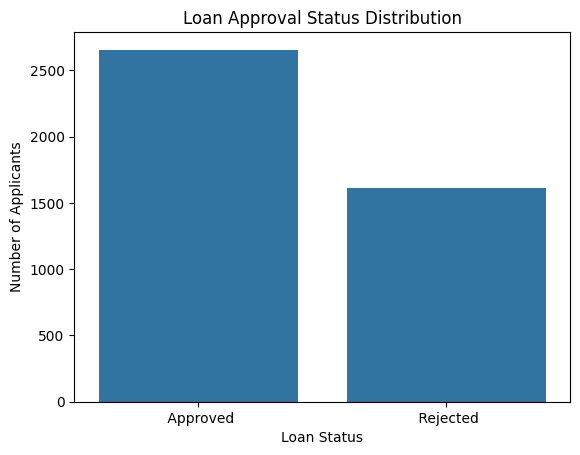

In [ ]:

print("Distribusi status pinjaman:")
print(df['loan_status'].value_counts())

print("\nDistribusi dalam persentase:")
print(
    (df['loan_status'].value_counts(normalize=True) * 100).round(2)
)

sns.countplot(data=df, x='loan_status')
plt.title('Loan Approval Status Distribution')
plt.xlabel('Loan Status')
plt.ylabel('Number of Applicants')
plt.show()


             count    mean  median  min  max
loan_status                                 
Approved      2656  703.46   711.0  300  900
Rejected      1613  429.47   429.0  300  885


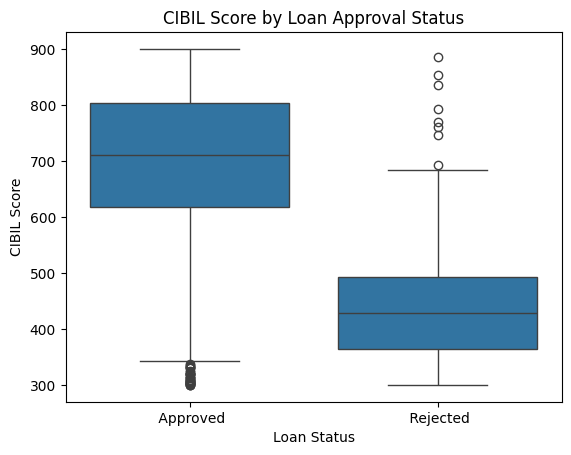

In [ ]:

# Ringkasan skor kredit berdasarkan status pinjaman
print(
    df.groupby('loan_status')['cibil_score']
      .agg(['count', 'mean', 'median', 'min', 'max'])
      .round(2)
)

# Visualisasi distribusi skor kredit
sns.boxplot(
    data=df,
    x='loan_status',
    y='cibil_score'
)

plt.title('CIBIL Score by Loan Approval Status')
plt.xlabel('Loan Status')
plt.ylabel('CIBIL Score')
plt.show()


            income_annum             loan_amount             loan_term       
                    mean     median         mean      median      mean median
loan_status                                                                  
Approved      5025903.61  5000000.0  15247251.51  14600000.0     10.40   10.0
Rejected      5113825.17  5100000.0  14946063.24  14500000.0     11.73   12.0


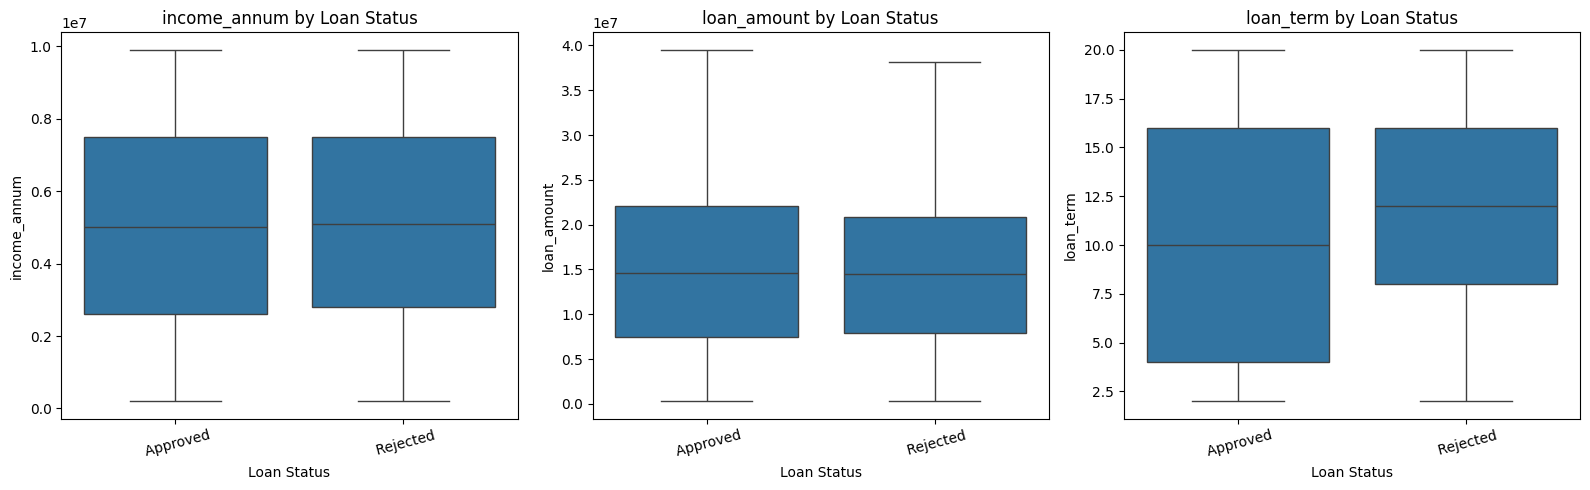

In [ ]:

# Membandingkan fitur finansial berdasarkan status pinjaman
features = ['income_annum', 'loan_amount', 'loan_term']

print(
    df.groupby('loan_status')[features]
      .agg(['mean', 'median'])
      .round(2)
)

# Visualisasi distribusi ketiga fitur
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, features):
    sns.boxplot(
        data=df,
        x='loan_status',
        y=col,
        ax=ax
    )
    ax.set_title(f'{col} by Loan Status')
    ax.set_xlabel('Loan Status')
    ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()



Distribusi loan_status berdasarkan education:


loan_status,Approved,Rejected
education,,
Graduate,62.45,37.55
Not Graduate,61.98,38.02


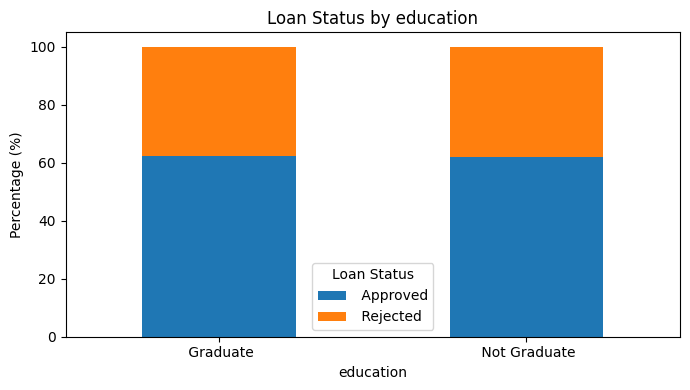


Distribusi loan_status berdasarkan self_employed:


loan_status,Approved,Rejected
self_employed,,
No,62.20,37.80
Yes,62.23,37.77


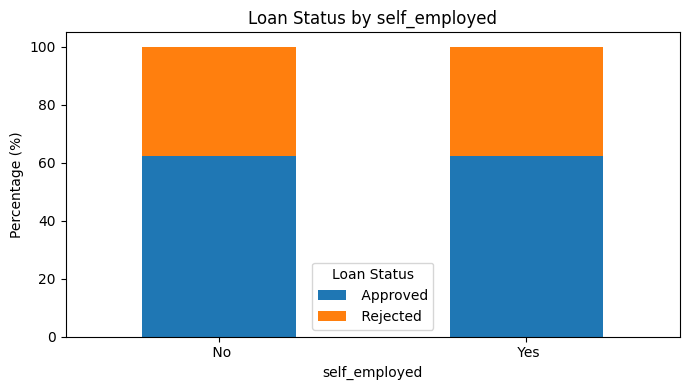

In [ ]:

# Persentase status pinjaman dalam setiap kategori
for col in ['education', 'self_employed']:
    print(f'\nDistribusi loan_status berdasarkan {col}:')

    result = pd.crosstab(
        df[col],
        df['loan_status'],
        normalize='index'
    ) * 100

    display(result.round(2))

    # Visualisasi persentase
    result.plot(
        kind='bar',
        stacked=True,
        figsize=(7, 4)
    )

    plt.title(f'Loan Status by {col}')
    plt.xlabel(col)
    plt.ylabel('Percentage (%)')
    plt.xticks(rotation=0)
    plt.legend(title='Loan Status')
    plt.tight_layout()
    plt.show()


In [ ]:

# Periksa tipe data dan kategori
print("Tipe data:")
print(df.dtypes)

print("\nKategori education:")
print(df['education'].value_counts())

print("\nKategori self_employed:")
print(df['self_employed'].value_counts())

print("\nKategori loan_status:")
print(df['loan_status'].value_counts())

# Pastikan tidak ada spasi tersembunyi pada nilai kategori
for col in ['education', 'self_employed', 'loan_status']:
    df[col] = df[col].astype(str).str.strip()

print("\nPemeriksaan selesai.")


Tipe data:
loan_id                      int64
no_of_dependents             int64
education                   object
self_employed               object
income_annum                 int64
loan_amount                  int64
loan_term                    int64
cibil_score                  int64
residential_assets_value     int64
commercial_assets_value      int64
luxury_assets_value          int64
bank_asset_value             int64
loan_status                 object
dtype: object

Kategori education:
education
Graduate        2144
Not Graduate    2125
Name: count, dtype: int64

Kategori self_employed:
self_employed
Yes    2150
No     2119
Name: count, dtype: int64

Kategori loan_status:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

Pemeriksaan selesai.


In [ ]:

from sklearn.model_selection import train_test_split

# Pisahkan fitur dan target
X = df.drop(columns=['loan_id', 'loan_status'])

y = df['loan_status'].map({
    'Rejected': 0,
    'Approved': 1
})

# Bagi data: 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])
print("\nDistribusi target training:")
print(y_train.value_counts())


Jumlah data training: 3415
Jumlah data testing: 854

Distribusi target training:
loan_status
1    2125
0    1290
Name: count, dtype: int64


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Pisahkan fitur numerik dan kategorikal
categorical_features = ['education', 'self_employed']

numeric_features = [
    col for col in X.columns
    if col not in categorical_features
]

# Preprocessing data numerik
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocessing data kategorikal
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Gabungkan preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Buat pipeline machine learning
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Latih model menggunakan data training
model.fit(X_train, y_train)

print("Model Logistic Regression berhasil dilatih!")


Model Logistic Regression berhasil dilatih!


Accuracy: 0.9145
ROC-AUC: 0.9726

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.90      0.87      0.88       323
    Approved       0.92      0.94      0.93       531

    accuracy                           0.91       854
   macro avg       0.91      0.91      0.91       854
weighted avg       0.91      0.91      0.91       854



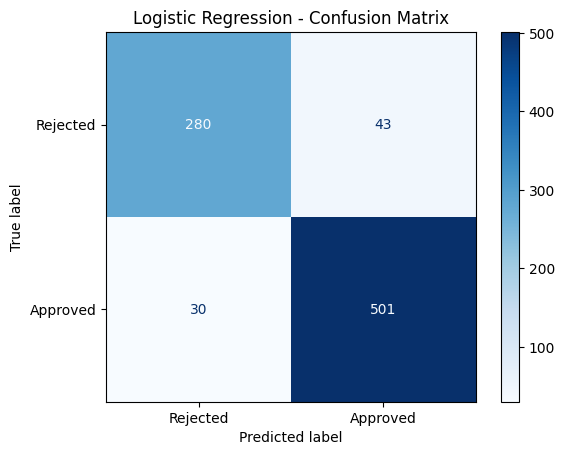

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)
import matplotlib.pyplot as plt

# Prediksi pada data testing
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Evaluasi performa
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=['Rejected', 'Approved'],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Rejected', 'Approved']
)

disp.plot(cmap='Blues')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()


In [ ]:

import pandas as pd
import numpy as np

# Ambil nama fitur setelah preprocessing
feature_names = model.named_steps[
    'preprocessor'
].get_feature_names_out()

# Ambil koefisien Logistic Regression
coefficients = model.named_steps[
    'classifier'
].coef_[0]

# Susun tabel koefisien
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Abs_Coefficient': np.abs(coefficients)
})

# Urutkan berdasarkan besarnya koefisien
feature_importance = feature_importance.sort_values(
    'Abs_Coefficient', ascending=False
)

print(feature_importance.to_string(index=False))


                      Feature  Coefficient  Abs_Coefficient
             num__cibil_score     4.094680         4.094680
            num__income_annum    -1.597191         1.597191
             num__loan_amount     1.322143         1.322143
               num__loan_term    -0.859486         0.859486
      cat__education_Graduate     0.459051         0.459051
       cat__self_employed_Yes     0.408895         0.408895
        cat__self_employed_No     0.378065         0.378065
  cat__education_Not Graduate     0.327909         0.327909
        num__bank_asset_value     0.178049         0.178049
     num__luxury_assets_value     0.129508         0.129508
 num__commercial_assets_value     0.092952         0.092952
        num__no_of_dependents    -0.076032         0.076032
num__residential_assets_value     0.042951         0.042951


In [ ]:

print(model.named_steps['preprocessor'])
print("\nIntercept model:")
print(model.named_steps['classifier'].intercept_)

print("\nKelas target:")
print(model.named_steps['classifier'].classes_)


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['no_of_dependents', 'income_annum',
                                  'loan_amount', 'loan_term', 'cibil_score',
                                  'residential_assets_value',
                                  'commercial_assets_value',
                                  'luxury_assets_value', 'bank_asset_value']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['ed

In [19]:

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report
import pandas as pd
import numpy as np

# Definisikan fitur numerik dan kategorikal
numeric_features = [
    'no_of_dependents', 'income_annum', 'loan_amount',
    'loan_term', 'cibil_score', 'residential_assets_value',
    'commercial_assets_value', 'luxury_assets_value',
    'bank_asset_value'
]

categorical_features = ['education', 'self_employed']

# Preprocessing numerik
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocessing kategorikal
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        drop='first'
    ))
])

# Gabungkan preprocessing
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Pipeline model baru
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Latih model
model.fit(X_train, y_train)

# Evaluasi
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.9145
ROC-AUC: 0.9726

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.87      0.88       323
           1       0.92      0.94      0.93       531

    accuracy                           0.91       854
   macro avg       0.91      0.91      0.91       854
weighted avg       0.91      0.91      0.91       854



In [20]:

feature_names = model.named_steps[
    'preprocessor'
].get_feature_names_out()

coefficients = model.named_steps[
    'classifier'
].coef_[0]

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Abs_Coefficient': np.abs(coefficients)
}).sort_values('Abs_Coefficient', ascending=False)

print(feature_importance.to_string(index=False))


                      Feature  Coefficient  Abs_Coefficient
             num__cibil_score     4.093618         4.093618
            num__income_annum    -1.592948         1.592948
             num__loan_amount     1.324906         1.324906
               num__loan_term    -0.859073         0.859073
        num__bank_asset_value     0.176800         0.176800
  cat__education_Not Graduate    -0.128264         0.128264
     num__luxury_assets_value     0.123500         0.123500
 num__commercial_assets_value     0.094111         0.094111
        num__no_of_dependents    -0.075662         0.075662
num__residential_assets_value     0.041248         0.041248
       cat__self_employed_Yes     0.033613         0.033613


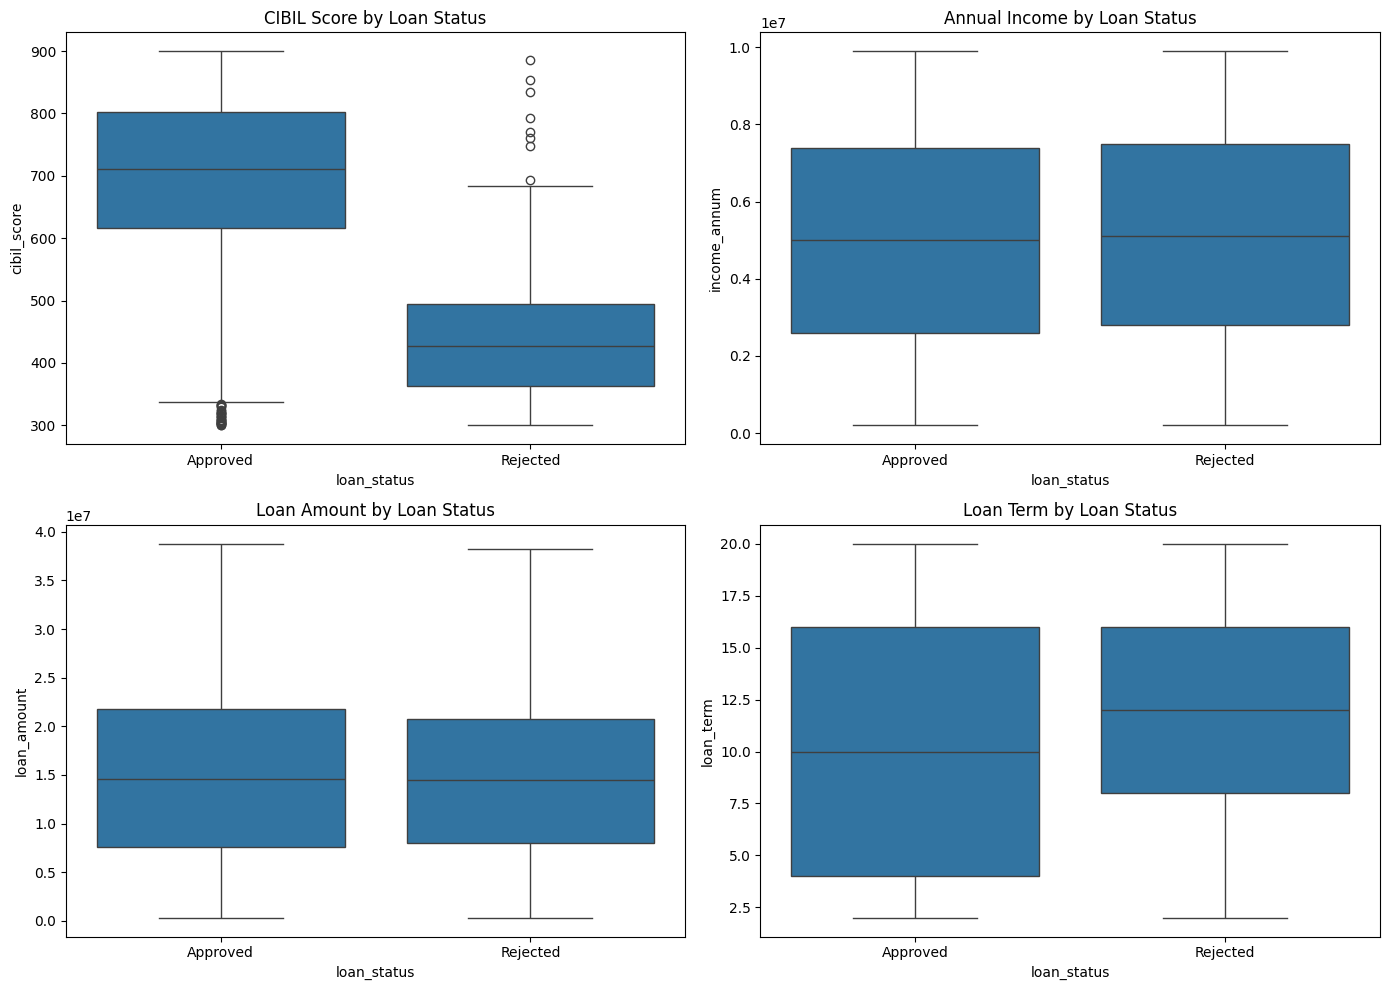

In [21]:

import matplotlib.pyplot as plt
import seaborn as sns

# Gabungkan fitur dan target training untuk visualisasi
eda_df = X_train.copy()
eda_df['loan_status'] = y_train.map({
    0: 'Rejected',
    1: 'Approved'
})

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(
    data=eda_df, x='loan_status',
    y='cibil_score', ax=axes[0, 0]
)
axes[0, 0].set_title('CIBIL Score by Loan Status')

sns.boxplot(
    data=eda_df, x='loan_status',
    y='income_annum', ax=axes[0, 1]
)
axes[0, 1].set_title('Annual Income by Loan Status')

sns.boxplot(
    data=eda_df, x='loan_status',
    y='loan_amount', ax=axes[1, 0]
)
axes[1, 0].set_title('Loan Amount by Loan Status')

sns.boxplot(
    data=eda_df, x='loan_status',
    y='loan_term', ax=axes[1, 1]
)
axes[1, 1].set_title('Loan Term by Loan Status')

plt.tight_layout()
plt.show()


In [22]:

from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Gunakan preprocessing yang sama dan latih Decision Tree
tree_model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('classifier', DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)

# Prediksi pada data testing yang sama
tree_pred = tree_model.predict(X_test)
tree_prob = tree_model.predict_proba(X_test)[:, 1]

# Simpan hasil evaluasi kedua model
results = pd.DataFrame([
    {
        'Model': 'Logistic Regression',
        'Accuracy': accuracy_score(
            y_test, model.predict(X_test)
        ),
        'Precision': precision_score(
            y_test, model.predict(X_test), zero_division=0
        ),
        'Recall': recall_score(
            y_test, model.predict(X_test), zero_division=0
        ),
        'F1-score': f1_score(
            y_test, model.predict(X_test), zero_division=0
        ),
        'ROC-AUC': roc_auc_score(
            y_test, model.predict_proba(X_test)[:, 1]
        )
    },
    {
        'Model': 'Decision Tree',
        'Accuracy': accuracy_score(y_test, tree_pred),
        'Precision': precision_score(
            y_test, tree_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_test, tree_pred, zero_division=0
        ),
        'F1-score': f1_score(
            y_test, tree_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_test, tree_prob)
    }
])

print(results.round(4).to_string(index=False))


              Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression    0.9145     0.9210  0.9435    0.9321   0.9726
      Decision Tree    0.9684     0.9828  0.9661    0.9744   0.9884


In [25]:

from sklearn.metrics import accuracy_score

# Evaluasi pada data training
tree_train_pred = tree_model.predict(X_train)

# Evaluasi pada data testing
tree_test_pred = tree_model.predict(X_test)

print("Training Accuracy:", round(accuracy_score(y_train, tree_train_pred), 4))
print("Testing Accuracy :", round(accuracy_score(y_test, tree_test_pred), 4))


Training Accuracy: 0.9742
Testing Accuracy : 0.9684


                      Feature  Importance
             num__cibil_score    0.871883
               num__loan_term    0.090788
             num__loan_amount    0.024459
            num__income_annum    0.010558
num__residential_assets_value    0.002040
 num__commercial_assets_value    0.000272
        num__no_of_dependents    0.000000
     num__luxury_assets_value    0.000000
        num__bank_asset_value    0.000000
  cat__education_Not Graduate    0.000000
       cat__self_employed_Yes    0.000000


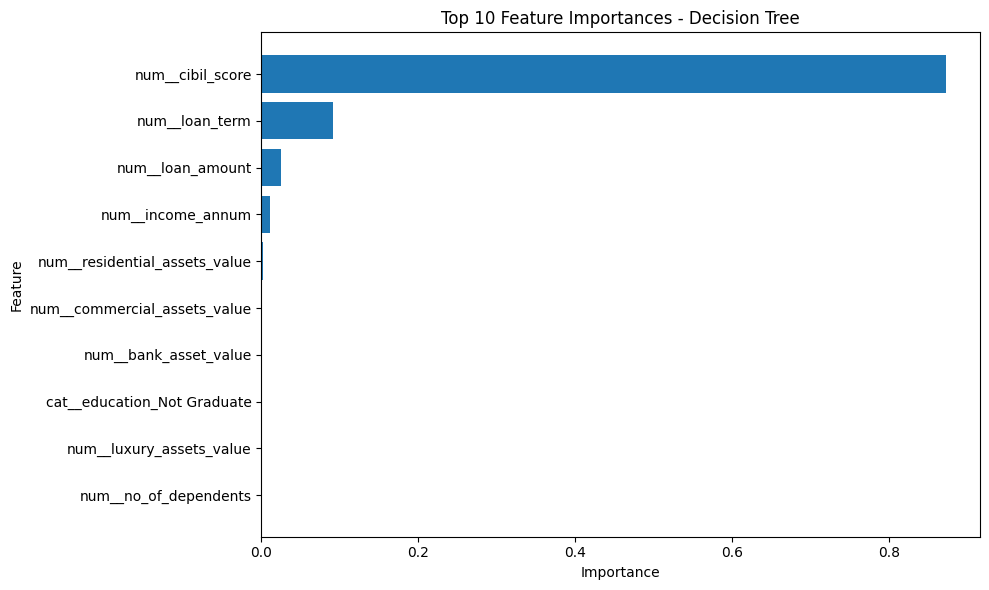

In [26]:

import pandas as pd
import matplotlib.pyplot as plt

# Ambil model Decision Tree dari pipeline
dt = tree_model.named_steps['classifier']

# Ambil nama fitur setelah preprocessing
preprocessor = tree_model.named_steps['preprocessor']
feature_names = preprocessor.get_feature_names_out()

# Buat tabel feature importance
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': dt.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance', ascending=False
)

print(importance_df.to_string(index=False))

# Visualisasi 10 fitur terpenting
top_features = importance_df.head(10).sort_values('Importance')

plt.figure(figsize=(10, 6))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.title('Top 10 Feature Importances - Decision Tree')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


Classification Report - Decision Tree
              precision    recall  f1-score   support

    Rejected       0.95      0.97      0.96       323
    Approved       0.98      0.97      0.97       531

    accuracy                           0.97       854
   macro avg       0.96      0.97      0.97       854
weighted avg       0.97      0.97      0.97       854



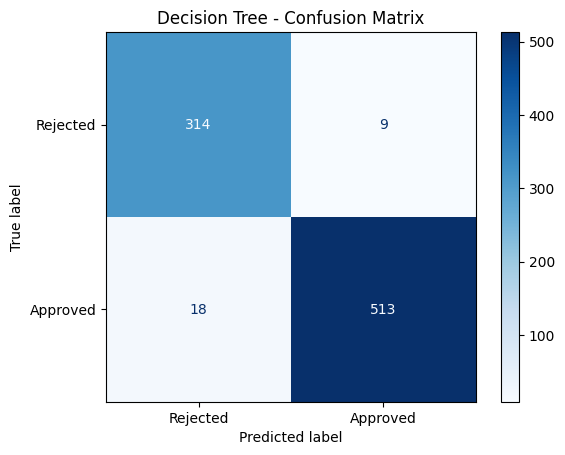

In [27]:

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Prediksi pada data testing
tree_test_pred = tree_model.predict(X_test)

print("Classification Report - Decision Tree")
print(classification_report(
    y_test,
    tree_test_pred,
    target_names=["Rejected", "Approved"]
))

cm = confusion_matrix(y_test, tree_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rejected", "Approved"]
)

disp.plot(cmap="Blues")
plt.title("Decision Tree - Confusion Matrix")
plt.show()


In [28]:

from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Akurasi setiap fold:", cv_scores.round(4))
print("Rata-rata akurasi:", round(cv_scores.mean(), 4))
print("Standar deviasi:", round(cv_scores.std(), 4))


Akurasi setiap fold: [0.9707 0.9649 0.959  0.9605 0.9619]
Rata-rata akurasi: 0.9634
Standar deviasi: 0.0041


In [29]:

# Memasukkan data pemohon baru
pemohon_baru = pd.DataFrame([{
    'no_of_dependents': 2,
    'education': 'Graduate',
    'self_employed': 'No',
    'income_annum': 8000000,
    'loan_amount': 15000000,
    'loan_term': 10,
    'cibil_score': 750,
    'residential_assets_value': 5000000,
    'commercial_assets_value': 3000000,
    'luxury_assets_value': 10000000,
    'bank_asset_value': 4000000
}])

# Prediksi menggunakan model Decision Tree
prediksi = tree_model.predict(pemohon_baru)[0]
probabilitas = tree_model.predict_proba(pemohon_baru)[0]

# Menampilkan hasil
label = {0: 'Rejected', 1: 'Approved'}

print("=== HASIL PREDIKSI PINJAMAN ===")
print("Status prediksi:", label[prediksi])
print(f"Probabilitas Rejected: {probabilitas[0]:.2%}")
print(f"Probabilitas Approved: {probabilitas[1]:.2%}")


=== HASIL PREDIKSI PINJAMAN ===
Status prediksi: Approved
Probabilitas Rejected: 0.00%
Probabilitas Approved: 100.00%


In [30]:

import ipywidgets as widgets
from IPython.display import display, clear_output

# Form input data pemohon
dependents = widgets.IntSlider(
    value=2, min=0, max=10, description='Tanggungan:'
)
education = widgets.Dropdown(
    options=['Graduate', 'Not Graduate'],
    description='Pendidikan:'
)
self_employed = widgets.Dropdown(
    options=['No', 'Yes'], description='Wiraswasta:'
)
income = widgets.IntText(
    value=8000000, description='Pendapatan/tahun:'
)
loan_amount = widgets.IntText(
    value=15000000, description='Jumlah pinjaman:'
)
loan_term = widgets.IntSlider(
    value=10, min=2, max=20, step=2, description='Tenor:'
)
cibil = widgets.IntSlider(
    value=750, min=300, max=900, description='CIBIL Score:'
)
residential = widgets.IntText(
    value=5000000, description='Aset residensial:'
)
commercial = widgets.IntText(
    value=3000000, description='Aset komersial:'
)
luxury = widgets.IntText(
    value=10000000, description='Aset mewah:'
)
bank_asset = widgets.IntText(
    value=4000000, description='Aset bank:'
)

tombol = widgets.Button(
    description='Prediksi Status Pinjaman',
    button_style='primary'
)
output = widgets.Output()

def prediksi_pinjaman(b):
    with output:
        clear_output()
        data = pd.DataFrame([{
            'no_of_dependents': dependents.value,
            'education': education.value,
            'self_employed': self_employed.value,
            'income_annum': income.value,
            'loan_amount': loan_amount.value,
            'loan_term': loan_term.value,
            'cibil_score': cibil.value,
            'residential_assets_value': residential.value,
            'commercial_assets_value': commercial.value,
            'luxury_assets_value': luxury.value,
            'bank_asset_value': bank_asset.value
        }])

        if min(income.value, loan_amount.value,
               residential.value, commercial.value,
               luxury.value, bank_asset.value) < 0:
            print("Nilai tidak boleh negatif.")
            return

        hasil = tree_model.predict(data)[0]
        prob = tree_model.predict_proba(data)[0]
        label = {0: 'Rejected', 1: 'Approved'}

        print("HASIL PREDIKSI")
        print("Status:", label[hasil])
        print(f"Probabilitas Rejected: {prob[0]:.2%}")
        print(f"Probabilitas Approved: {prob[1]:.2%}")
        print("\nHasil ini merupakan prediksi model,")
        print("bukan keputusan resmi dari bank.")

tombol.on_click(prediksi_pinjaman)

display(widgets.VBox([
    dependents, education, self_employed,
    income, loan_amount, loan_term, cibil,
    residential, commercial, luxury, bank_asset,
    tombol, output
]))
